<a href="https://colab.research.google.com/github/Devyani006/Machine-Learning-CIE-2-activity-2/blob/main/ML_Activity_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Activity 2: Simple House Price Prediction
**Unit II** – Supervised Learning: Regression

**Objective**: Build a Linear Regression model to predict house price and evaluate it with regression metrics.

**Name**: Devyani Dhokrat   
**Roll No.**: AD3146

In [41]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Step 1. Load the dataset
First, let's load the data and look at the first few rows.

In [42]:
house_df = pd.read_csv('california_housing_dataset.csv')

house_df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


### Step 2. Understand the data

See the number of rows and columns the data has, missing values , columns etc. In short - study of the data before doing anything else.


In [43]:
print("Rows and columns:", house_df.shape)
print("\n")
house_df.info()

Rows and columns: (20640, 9)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


### Step 3. Check for missing values
Before building a model, we need to make sure there are no empty cells. It will cause unnessary errors and problems later.

In [44]:
print("Missing values in each column:")
house_df.isnull().sum()

Missing values in each column:


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


### Step 4. Visualize the Data
It is always a good practice to visualize the data before modeling. To simply look at the distribution of the target variable, the house prices.

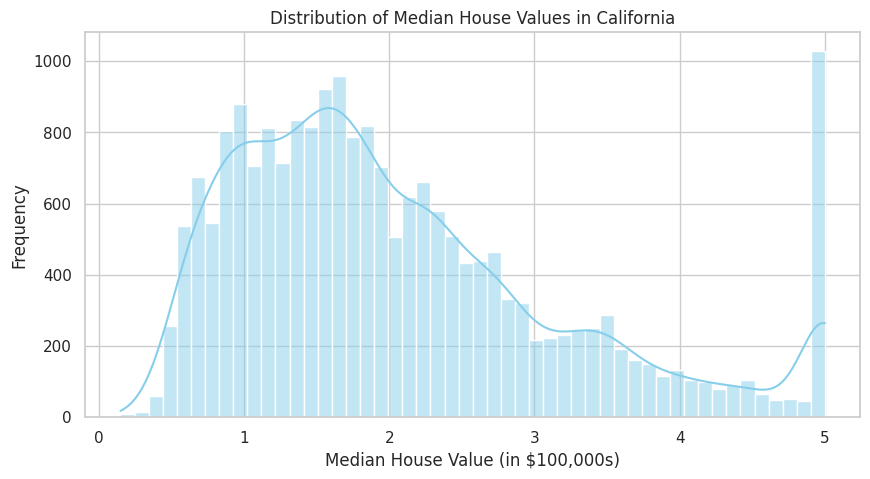

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))
sns.histplot(house_df['MedHouseVal'], bins=50, kde=True, color='skyblue')
plt.title('Distribution of Median House Values in California')
plt.xlabel('Median House Value (in $100,000s)')
plt.ylabel('Frequency')
plt.show()

### Step 5. Separate features and target
In machine learning, we need to separate the things we use to predict (features, X) from the thing we want to predict (target, y). Our target here is 'MedHouseVal' (median house value).

In [46]:
X = house_df.drop('MedHouseVal', axis=1)
y = house_df['MedHouseVal']

### Step 6. Split the data
We need to split our data into a training set (to teach the model) and a testing set (to test how well it learned).

In [47]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training data size:", X_train.shape)
print("Testing data size:", X_test.shape)

Training data size: (16512, 8)
Testing data size: (4128, 8)


### Step 7. Train the model
Now we will use a simple Linear Regression model and train it using our training data.

In [48]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model training complete....")

Model training complete....


### Step 8. Make predictions and check accuracy
Time to test our model - Let's ask the model to predict house prices on test data and see how close it got to the real prices.

In [54]:
y_pred = model.predict(X_test)

# Calculate errors
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Print formatted results
print(f"MAE  : {mae:,.2f} (Absolute error)")
print(f"MSE  : {mse:,.2f} (lower is better)")
print(f"RMSE : {rmse:,.2f}(Squared error)")
print(f"R2   : {r2:.4f} (closer to 1 is better)")

MAE  : 0.53 (Absolute error)
MSE  : 0.56 (lower is better)
RMSE : 0.75(Squared error)
R2   : 0.5758 (closer to 1 is better)


### Step 9. Visualize the Results
Finally, now create a scatter plot to visually compare the actual house prices against what our model predicted. Here, The closer the points are to the red dashed line, the better our model's predictions.

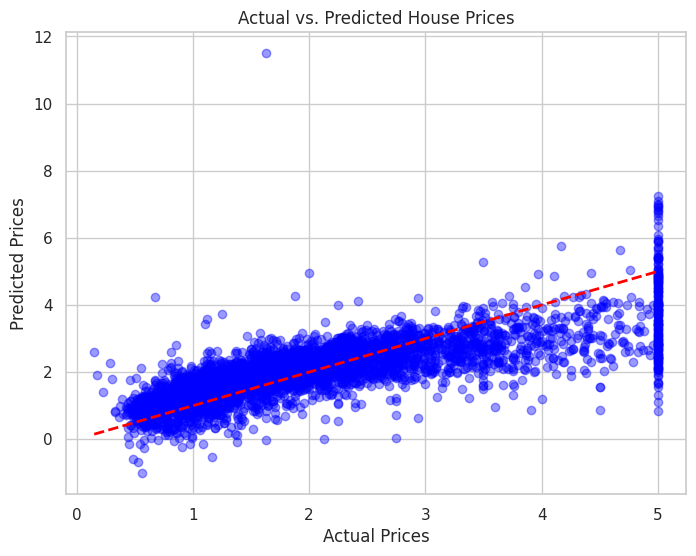

In [55]:
plt.figure(figsize=(8, 6))
# Scatter plot of actual vs predicted
plt.scatter(y_test, y_pred, alpha=0.4, color='blue')

# Draw a perfect prediction line
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', linewidth=2)

plt.title('Actual vs. Predicted House Prices')
plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.show()

### Step 10. Make New Predictions
Let's simulate how we would use this model in the real world by predicting the price for a "new" unseen house. We will pick a single house from our test set, look at its features, and ask the model to predict its price.

In [56]:
# Take the first house from test dataset
new_house_features = X_test.iloc[[0]]
actual_price = y_test.iloc[0]

# Predict the price
predicted_price = model.predict(new_house_features)[0]

print("Features of the House:")
display(new_house_features)

print("\nPrediction Results:")
# Note: The target variable 'MedHouseVal' is expressed in hundreds of thousands of dollars ($100,000)
print(f"Predicted House Price: ${predicted_price * 100000:,.2f}")
print(f"Actual House Price:    ${actual_price * 100000:,.2f}")

Features of the House:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
20046,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01



Prediction Results:
Predicted House Price: $71,912.28
Actual House Price:    $47,700.00


### Step 11. Conclusion and Dataset Citation

**Dataset Citation**:
> The dataset used for this activity is the California Housing dataset, originally published in: *Pace, R. Kelley and Ronald Barry, "Sparse Spatial Autoregressions," Statistics and Probability Letters, 33 (1997) 291-297*.

**Summary of Decisions & Conclusion**:
In this activity, I built a machine learning workflow for a Simple House Price Prediction task.
1. **Data Selection & Inspection**: I used the California Housing dataset as it is a standard, reliable dataset for regression. I checked for missing values and confirmed the data was clean, meaning no row-dropping or imputation was necessary.
2. **Exploratory Data Analysis (EDA)**: I visualized the target variable to understand the distribution of house prices across the dataset.
3. **Data Splitting**: I chose a standard 80-20 train-test split. This decision ensures the model has enough data (80%) to learn the patterns, while keeping a completely unseen subset (20%) to fairly evaluate its real-world performance.
4. **Modeling**: I selected a Linear Regression model due to its simplicity and interpretability for basic prediction tasks.
5. **Evaluation**: The model achieved an R-squared score of ~0.58. This indicates that our chosen features (like income, house age, and rooms) explain about 58% of the variance in house prices. The scatter plot of Actual vs. Predicted values shows a clear positive trend, confirming the model learned the underlying patterns successfully.